# Wstępna inferencja na zdjęciach z drona

Model trenowany na DeepCrack (zdjęcia z bliska) uruchomiony na zdjęciach nadirowych z nalotu (DJI M4E, ~35 m).
Cel: zobaczyć **różnicę domenową** - jak model myli się na nowych danych, a nie zmierzyć dokładność (brak masek).

1. Całe zdjęcia w skali 1× (kafelkowanie z nakładką).
2. Wycinek drogi w skalach 1×, 2×, 3× - czy powiększenie (dopasowanie szerokości pęknięć do DeepCrack) pomaga.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import cv2
import numpy as np
import torch
import albumentations as A
import matplotlib.pyplot as plt

from crackseg.model import CrackSegModel

DRONE_DIR = Path(r"C:/Studia/inz/data_for_cracks/BIM_dane/BIM_dane/Orto")
FIG_DIR = Path("outputs/figures/drone")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TILE = 512        # rozmiar kafla (podzielny przez 32)
STRIDE = 384      # krok -> nakładka 128 px
BATCH = 4         # kafli naraz (na CPU małe, żeby nie zabrakło RAM)
THRESHOLDS = (0.3, 0.5)

CKPT = max(Path("outputs").glob("*/*/checkpoints/*.ckpt"), key=lambda p: p.stat().st_mtime)
model = CrackSegModel.load_from_checkpoint(CKPT, map_location="cpu").eval()
normalize = A.Normalize()   # te same statystyki ImageNet co w CrackDataset

images = sorted(DRONE_DIR.glob("*.JPG"))
print("checkpoint:", CKPT)
print("zdjęć:", len(images))

C:\Studia\inz\crack__detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


checkpoint: outputs\1\346da2418a2c483cb8de8505168b5461\checkpoints\epoch=45-step=1426.ckpt
zdjęć: 23


In [2]:
def load_rgb(path) -> np.ndarray:
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def _starts(length: int) -> list[int]:
    """początki kafli wzdłuż jednej osi, ostatni kafel dosunięty do końca"""
    if length <= TILE:
        return [0]
    starts = list(range(0, length - TILE + 1, STRIDE))
    if starts[-1] != length - TILE:
        starts.append(length - TILE)
    return starts


@torch.no_grad()
def predict_tiled(img: np.ndarray) -> np.ndarray:
    """RGB uint8 (H,W,3) -> mapa prawdopodobieństwa (H,W), kafle z nakładką uśredniane"""
    h, w = img.shape[:2]
    pad_h, pad_w = max(0, TILE - h), max(0, TILE - w)          # obraz mniejszy niż kafel
    img_p = cv2.copyMakeBorder(img, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT)
    x = normalize(image=img_p)["image"]                       # float32, (H,W,3)
    H, W = x.shape[:2]

    prob_sum = np.zeros((H, W), np.float32)
    count = np.zeros((H, W), np.float32)
    coords = [(y, x0) for y in _starts(H) for x0 in _starts(W)]

    for i in range(0, len(coords), BATCH):
        chunk = coords[i:i + BATCH]
        tiles = np.stack([x[y:y + TILE, x0:x0 + TILE] for y, x0 in chunk])
        batch = torch.from_numpy(tiles).permute(0, 3, 1, 2)    # (B,3,TILE,TILE)
        probs = model(batch).sigmoid()[:, 0].numpy()
        for (y, x0), p in zip(chunk, probs):
            prob_sum[y:y + TILE, x0:x0 + TILE] += p
            count[y:y + TILE, x0:x0 + TILE] += 1

    return (prob_sum / count)[:h, :w]


def overlay(img: np.ndarray, mask: np.ndarray, color=(255, 0, 0)) -> np.ndarray:
    out = img.copy()
    out[mask] = color
    return out


def show(img, prob, title, max_side=1600, save_as=None):
    """obraz | prawdopodobieństwo | maska dla każdego progu; do wyświetlenia zmniejszone"""
    s = min(1.0, max_side / max(img.shape[:2]))
    small = lambda a, interp: cv2.resize(a, None, fx=s, fy=s, interpolation=interp)
    # maskę zmniejszamy przez max-pooling (INTER_AREA na bool zgubiłby cienkie linie)
    panels = [(small(img, cv2.INTER_AREA), "obraz"),
              (small(prob, cv2.INTER_AREA), "prawdopodobieństwo")]
    for t in THRESHOLDS:
        m = prob > t
        if s < 1:
            k = max(1, int(round(1 / s)))
            m = cv2.dilate(m.astype(np.uint8), np.ones((k, k), np.uint8)) > 0
        panels.append((overlay(small(img, cv2.INTER_AREA), small(m.astype(np.uint8), cv2.INTER_NEAREST) > 0),
                       f"próg {t}  ({(prob > t).mean() * 100:.2f}% px)"))

    fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 5))
    for ax, (p, name) in zip(axes, panels):
        if p.ndim == 2:
            ax.imshow(p, vmin=0, vmax=1, cmap="magma")
        else:
            ax.imshow(p)
        ax.set_title(name); ax.axis("off")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    if save_as:
        fig.savefig(FIG_DIR / save_as, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Całe zdjęcia, skala 1×

DJI_20261008142757_0023_V.JPG: 5280x3956, 36 s, max p = 1.00


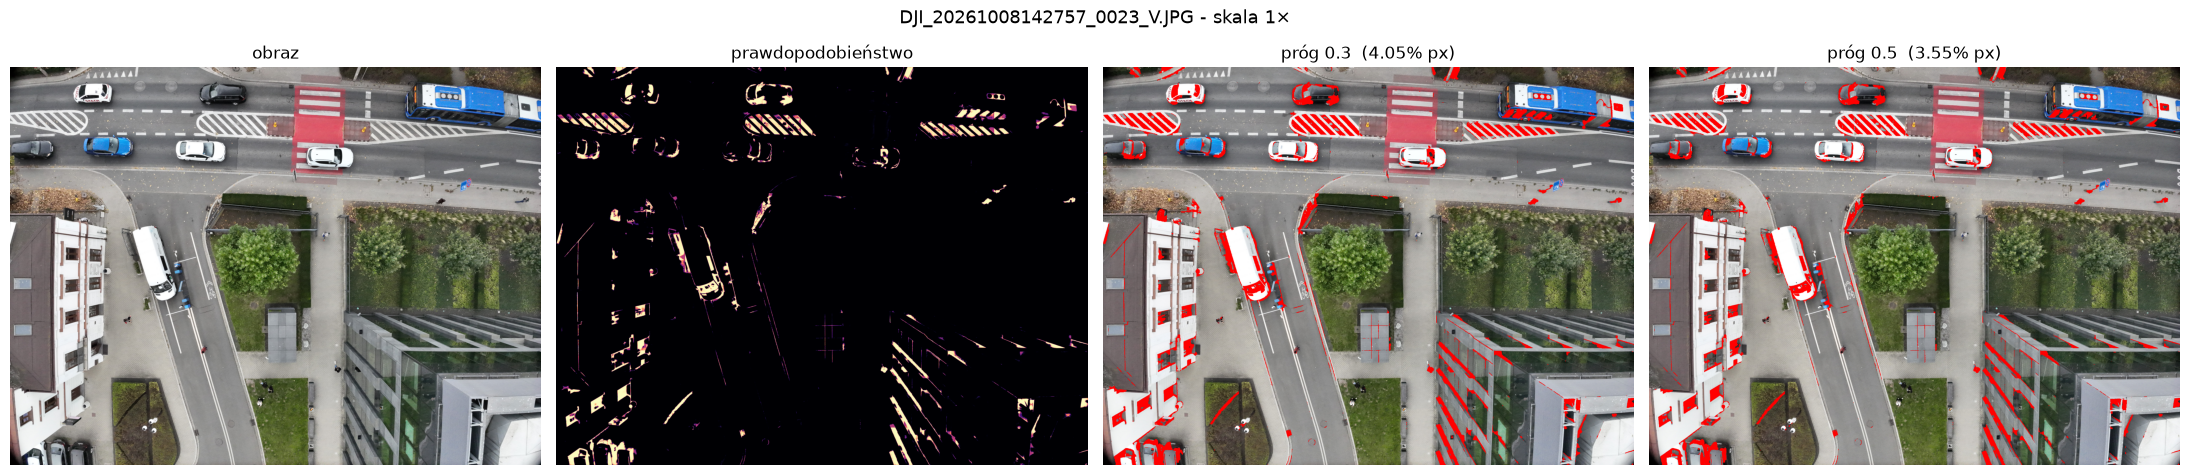

DJI_20261008142813_0025_V.JPG: 5280x3956, 35 s, max p = 1.00


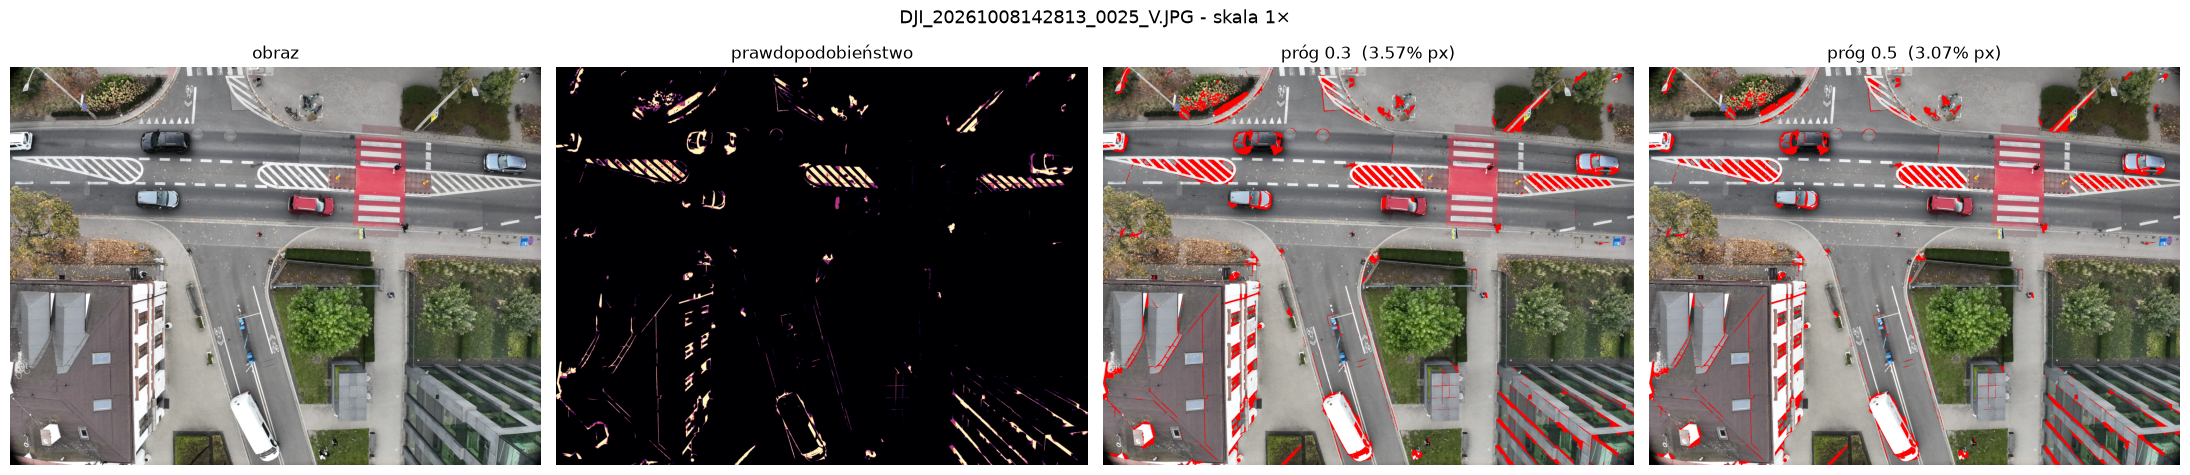

In [6]:
import time

for idx in (5, 7):
    img = load_rgb(images[idx])
    t0 = time.time()
    prob = predict_tiled(img)
    print(f"{images[idx].name}: {img.shape[1]}x{img.shape[0]}, {time.time() - t0:.0f} s, "
          f"max p = {prob.max():.2f}")
    show(img, prob, f"{images[idx].name} - skala 1×", save_as=f"full_{idx:02d}.png")

## 2. Wycinek drogi w kilku skalach

Na DeepCrack pęknięcia mają kilkanaście px szerokości, tu (GSD ~1 cm/px) - kilka px.
Powiększenie przed predykcją sprawdza, czy model „widzi” pęknięcia, gdy ich skala zbliży się do treningowej.

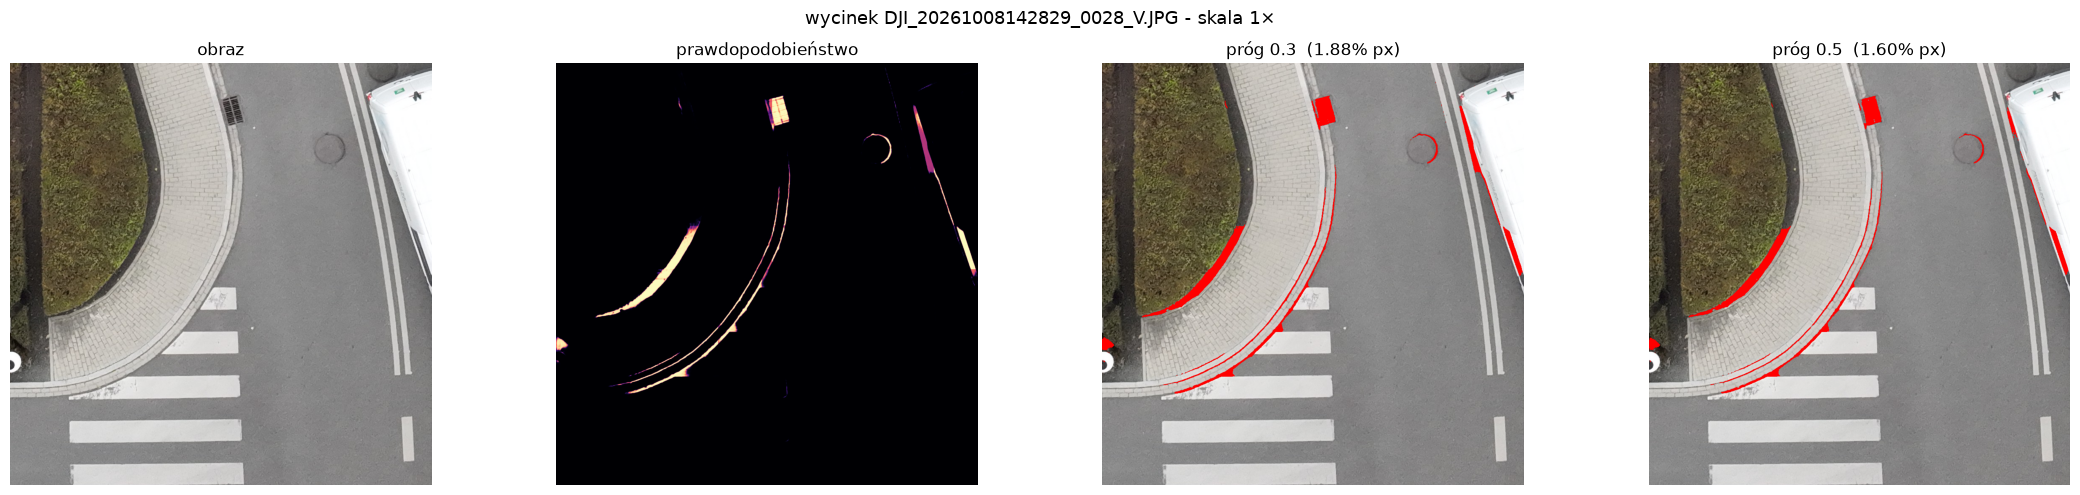

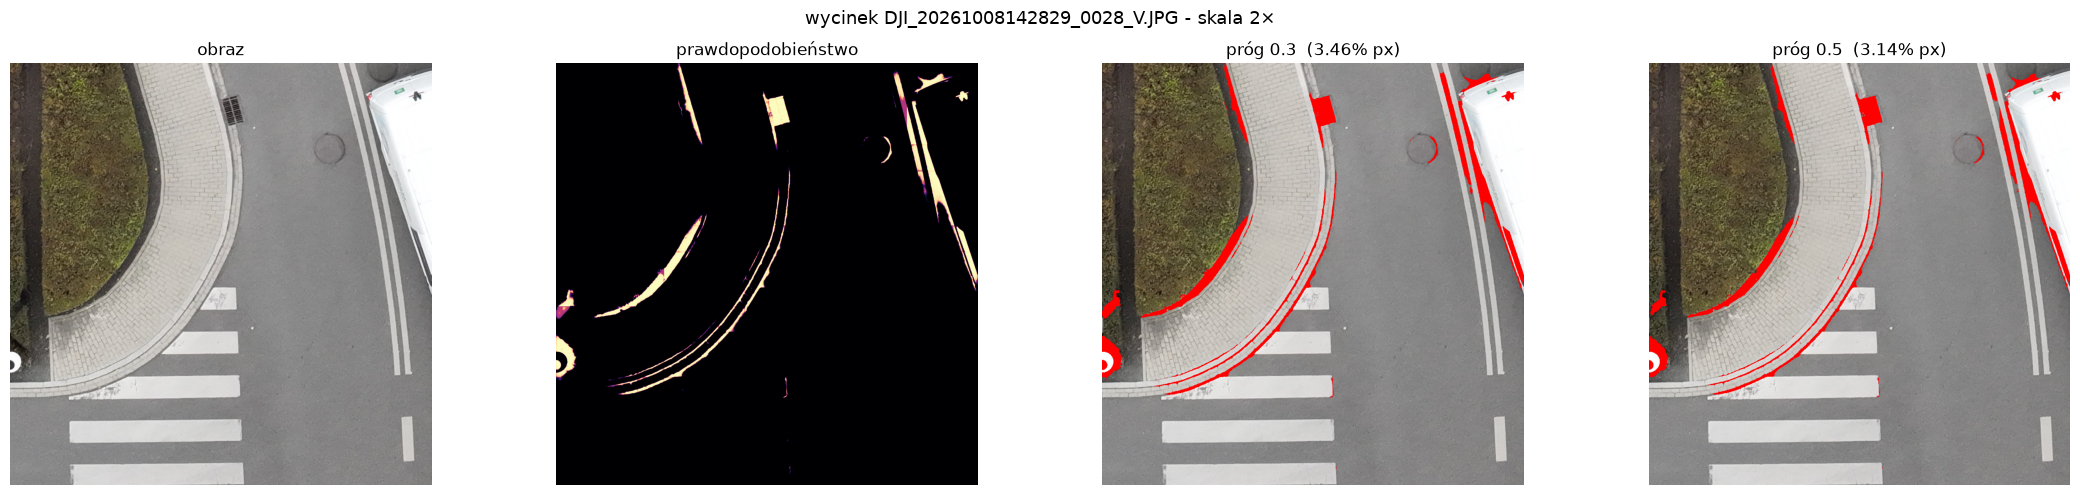

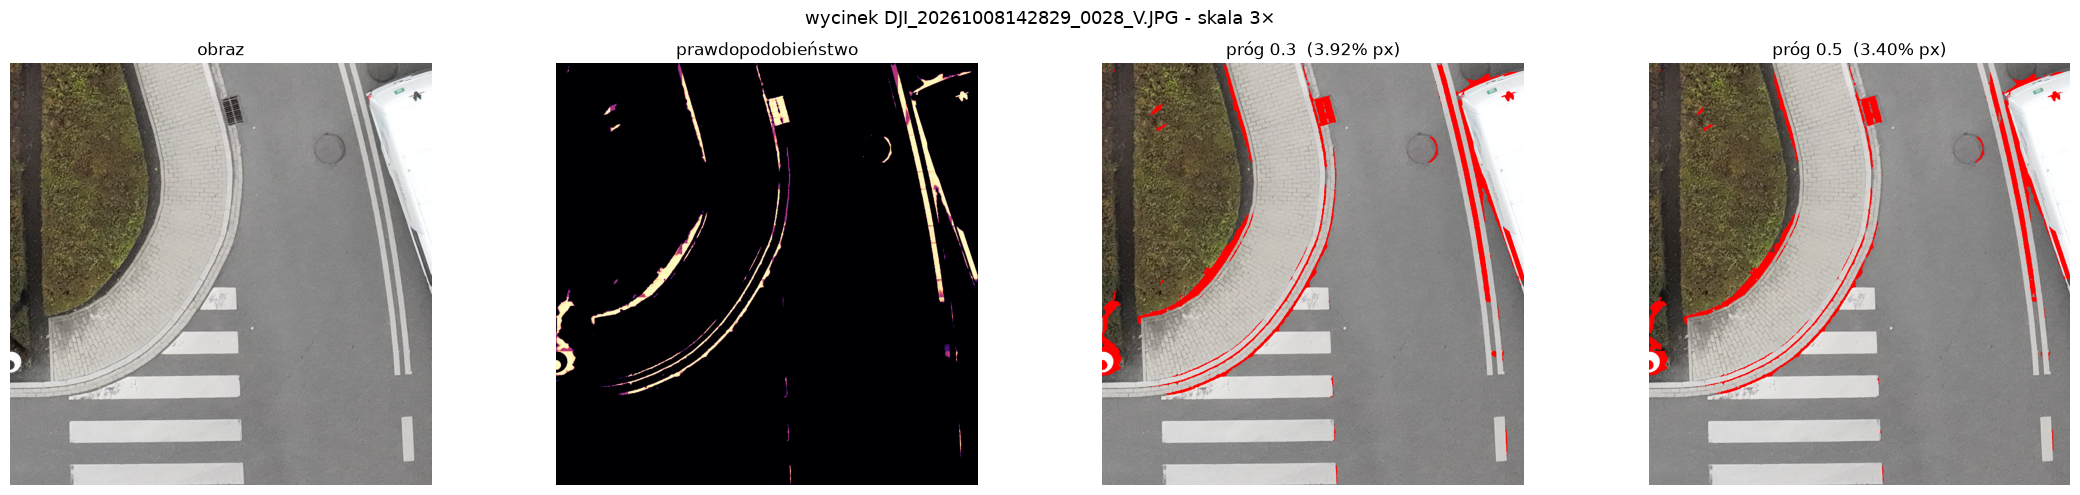

In [4]:
CROP_IMG, (Y0, Y1, X0, X1) = 10, (2400, 3400, 1900, 2900)   # droga, przejście, kostka, krawężnik
crop = load_rgb(images[CROP_IMG])[Y0:Y1, X0:X1]

for scale in (1, 2, 3):
    big = cv2.resize(crop, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC) if scale > 1 else crop
    prob = predict_tiled(big)
    # z powrotem do rozmiaru wycinka, żeby skale były porównywalne
    prob = cv2.resize(prob, (crop.shape[1], crop.shape[0]), interpolation=cv2.INTER_AREA)
    show(crop, prob, f"wycinek {images[CROP_IMG].name} - skala {scale}×", save_as=f"crop_scale{scale}.png")